# รวมชุดข้อมูลใน `clean_data_set`

รวมข้อมูลฝนรายเดือน น้ำท่วมรายเดือน ความชื้น/ฝนรายวัน ปริมาณน้ำรายเดือน และระดับน้ำทะเลรายเดือนจากปี 2020–2025 โดยใช้คีย์อำเภอและช่วงเวลาเดียวกัน มี EDA พร้อมกราฟก่อน Clean/Data Prep และหลังรวมข้อมูล โดยผลลัพธ์หนึ่งแถวต่ออำเภอ-ปี-เดือน

Sea-level records are joined by district, year, and month. Missing source measurements are retained.

## 1. โหลดไฟล์ CSV จาก `clean_data_set`

ตรวจสอบว่าไฟล์ต้นทางทั้ง 5 ชุดมีอยู่ โหลดจาก clean_data_set และเลือกเฉพาะปี 2020–2025

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / 'clean_data_set').is_dir()), None)
if root is None:
    raise FileNotFoundError('ไม่พบโฟลเดอร์ clean_data_set จากตำแหน่งปัจจุบันหรือโฟลเดอร์แม่')

data_dir = root / 'clean_data_set'
source_files = {
    'flood': 'NST_amphoe_monthly_flood_2020_2025_clean.csv',
    'rain': 'NST_amphoe_monthly_rain_maxmin_2020_2025_clean.csv',
    'humidity_daily': 'NST_district_daily_humidity_2020_2025_clean.csv',
    'river_monthly': 'NST_district_monthly_river_volume_2020_2025_clean.csv',
    'sea_level': 'NST_district_monthly_sea_level_2020_2025_clean.csv',
}
missing_files = [name for name in source_files.values() if not (data_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(f'ไม่พบไฟล์ CSV ที่ต้องใช้ใน {data_dir}: {missing_files}')

years = [2020, 2021, 2022, 2023, 2024, 2025]
datasets = {name: pd.read_csv(data_dir / filename) for name, filename in source_files.items()}
datasets = {
    name: frame.loc[frame['year'].isin(years)].copy()
    for name, frame in datasets.items()
}
for name, frame in datasets.items():
    print(f'{name}: {frame.shape[0]:,} แถว × {frame.shape[1]} คอลัมน์ | {source_files[name]}')
display(datasets['flood'].head())

flood: 1,296 แถว × 12 คอลัมน์ | NST_amphoe_monthly_flood_2020_2025_clean.csv
rain: 1,296 แถว × 9 คอลัมน์ | NST_amphoe_monthly_rain_maxmin_2020_2025_clean.csv
humidity_daily: 37,264 แถว × 13 คอลัมน์ | NST_district_daily_humidity_2020_2025_clean.csv
river_monthly: 1,296 แถว × 14 คอลัมน์ | NST_district_monthly_river_volume_2020_2025_clean.csv
sea_level: 1,296 แถว × 13 คอลัมน์ | NST_district_monthly_sea_level_2020_2025_clean.csv


,province,amphoe,year,month,month_start,month_th,flooded,flood_status,flood_events_month,flood_windows,max_flood_ha,flood_events_year
0,นครศรีธรรมราช,Bang Khan,2020,1,2020-01-01,มกราคม,0,ไม่ท่วม,0,0,0.000,0
1,นครศรีธรรมราช,Bang Khan,2020,2,2020-02-01,กุมภาพันธ์,0,ไม่ท่วม,0,0,0.000,0
2,นครศรีธรรมราช,Bang Khan,2020,3,2020-03-01,มีนาคม,0,ไม่ท่วม,0,0,0.000,0
3,นครศรีธรรมราช,Bang Khan,2020,4,2020-04-01,เมษายน,0,ไม่ท่วม,0,0,0.000,0
4,นครศรีธรรมราช,Bang Khan,2020,5,2020-05-01,พฤษภาคม,0,ไม่ท่วม,0,0,0.246,0


## 2. EDA ก่อน Clean และ Data Prep

สำรวจข้อมูล CSV ในช่วงปี 2020–2025 ที่โหลดมาก่อนปรับคีย์/ระดับเวลาเพื่อรวม โดยกราฟใช้ข้อมูลต้นทางแต่ละชุดในระดับเวลาที่เหมาะสมของชุดนั้น

flood: shape=(1296, 12), missing=0, duplicates=0
rain: shape=(1296, 9), missing=0, duplicates=0
humidity_daily: shape=(37264, 13), missing=0, duplicates=0
river_monthly: shape=(1296, 14), missing=72, duplicates=0
sea_level: shape=(1296, 13), missing=3447, duplicates=0


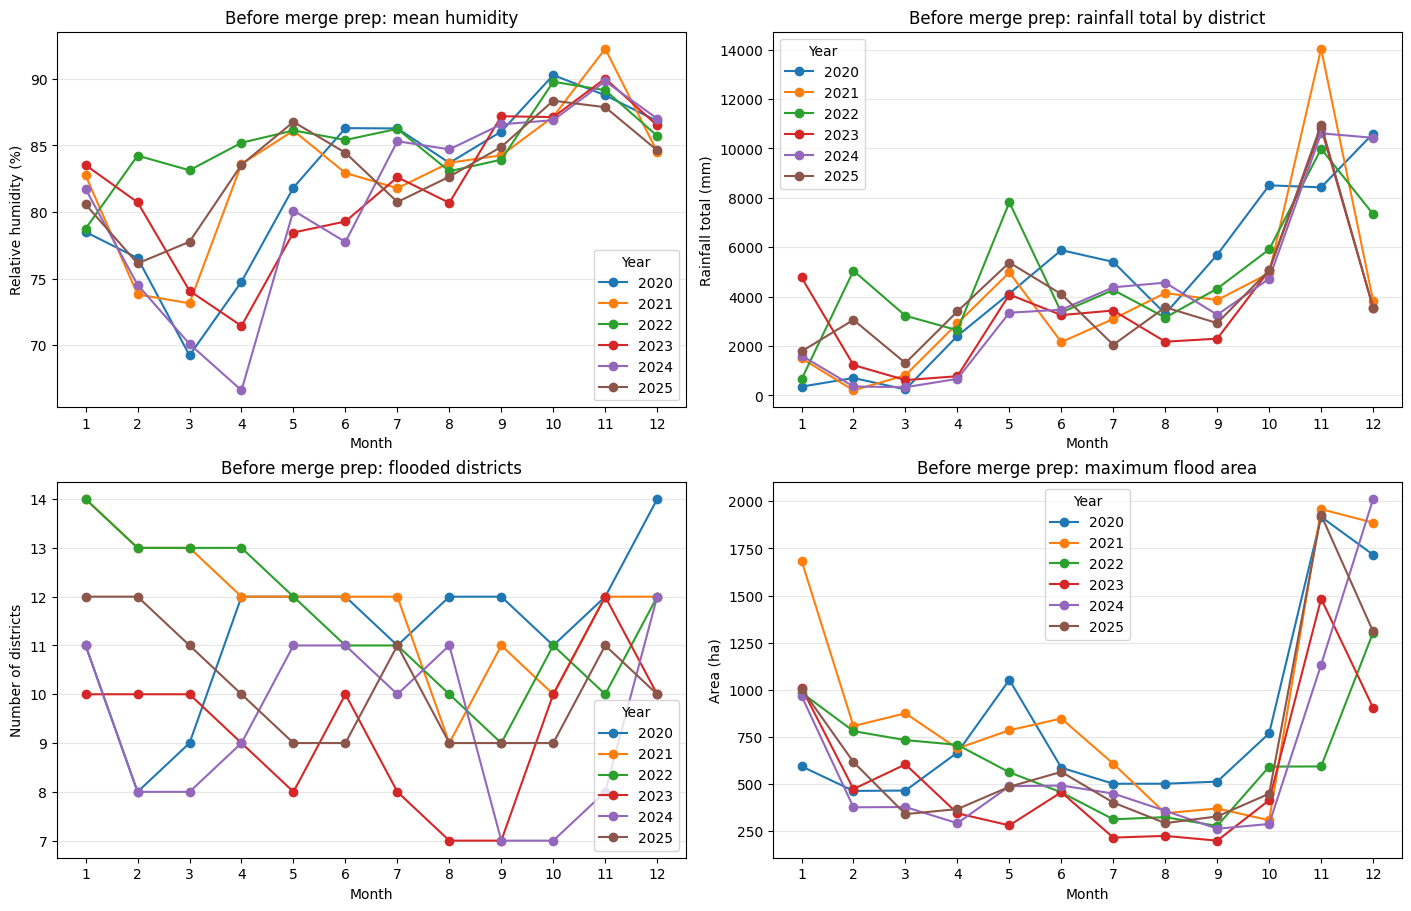

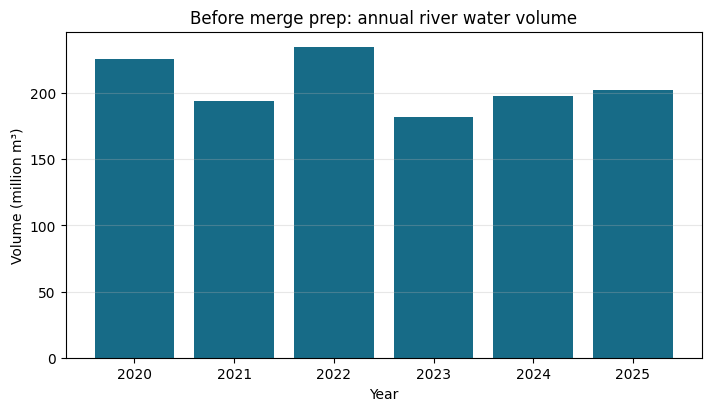

In [2]:
for name, frame in datasets.items():
    print(f'{name}: shape={frame.shape}, missing={int(frame.isna().sum().sum())}, duplicates={int(frame.duplicated().sum())}')

humidity_raw_monthly = datasets['humidity_daily'].copy()
humidity_raw_monthly['date'] = pd.to_datetime(humidity_raw_monthly['date'], errors='raise')
humidity_raw_monthly['year'] = humidity_raw_monthly['date'].dt.year
humidity_raw_monthly['month'] = humidity_raw_monthly['date'].dt.month
humidity_raw_monthly = humidity_raw_monthly.groupby(['year', 'month'], as_index=False).agg(
    mean_rh_pct=('rh_pct', 'mean'),
    mean_daily_rain_mm=('rain_mm', 'mean'),
)
rain_raw_monthly = datasets['rain'].groupby(['year', 'month'], as_index=False).agg(
    rain_total_across_districts_mm=('rain_total_mm', 'sum'),
)
flood_raw_monthly = datasets['flood'].groupby(['year', 'month'], as_index=False).agg(
    flooded_districts=('flooded', 'sum'),
    max_flood_area_sum_ha=('max_flood_ha', 'sum'),
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
for year in sorted(humidity_raw_monthly['year'].unique()):
    humidity_subset = humidity_raw_monthly.loc[humidity_raw_monthly['year'] == year]
    rain_subset = rain_raw_monthly.loc[rain_raw_monthly['year'] == year]
    flood_subset = flood_raw_monthly.loc[flood_raw_monthly['year'] == year]
    axes[0, 0].plot(humidity_subset['month'], humidity_subset['mean_rh_pct'], marker='o', label=str(year))
    axes[0, 1].plot(rain_subset['month'], rain_subset['rain_total_across_districts_mm'], marker='o', label=str(year))
    axes[1, 0].plot(flood_subset['month'], flood_subset['flooded_districts'], marker='o', label=str(year))
    axes[1, 1].plot(flood_subset['month'], flood_subset['max_flood_area_sum_ha'], marker='o', label=str(year))
axes[0, 0].set(title='Before merge prep: mean humidity', ylabel='Relative humidity (%)')
axes[0, 1].set(title='Before merge prep: rainfall total by district', ylabel='Rainfall total (mm)')
axes[1, 0].set(title='Before merge prep: flooded districts', ylabel='Number of districts')
axes[1, 1].set(title='Before merge prep: maximum flood area', ylabel='Area (ha)')
for ax in axes.flat:
    ax.set_xlabel('Month')
    ax.set_xticks(range(1, 13))
    ax.grid(axis='y', alpha=.3)
    ax.legend(title='Year')
display(fig)
plt.close(fig)

river_raw_annual = datasets['river_monthly'].groupby('year', as_index=False).agg(
    total_water_volume_mcm=('river_water_volume_mcm', 'sum'),
)
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.bar(river_raw_annual['year'].astype(str), river_raw_annual['total_water_volume_mcm'], color='#176B87')
ax.set(title='Before merge prep: annual river water volume', xlabel='Year', ylabel='Volume (million m³)')
ax.grid(axis='y', alpha=.3)
display(fig)
plt.close(fig)

## 3. Clean และ Data Prep ก่อนรวม

ใช้ชื่ออำเภอที่ตัดช่องว่างและไม่สนตัวพิมพ์เล็ก/ใหญ่เป็นคีย์มาตรฐาน ข้อมูลความชื้น/ฝนรายวันสรุปเป็นรายเดือน: ค่าอุณหภูมิ/ความชื้นเฉลี่ย, ฝนรวมและฝนสูงสุดรายวัน ส่วนจำนวนวัน `heavy` นับเฉพาะแถวที่มีข้อมูล

In [3]:
def normalize_district(values):
    return values.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True).str.casefold()

humidity_daily = datasets['humidity_daily'].copy()
humidity_daily['district_key'] = normalize_district(humidity_daily['district'])
humidity_daily['date'] = pd.to_datetime(humidity_daily['date'], errors='raise')
humidity_daily['year'] = humidity_daily['date'].dt.year.astype('int64')
humidity_daily['month'] = humidity_daily['date'].dt.month.astype('int64')

humidity_monthly = humidity_daily.groupby(
    ['district_key', 'year', 'month'], as_index=False
).agg(
    province=('province', 'first'),
    district=('district', 'first'),
    district_code=('district_code', 'first'),
    humidity_mean_rh_pct=('rh_pct', 'mean'),
    humidity_mean_q_gkg=('q_gkg', 'mean'),
    humidity_mean_dewpoint_c=('dewpoint_c', 'mean'),
    humidity_mean_temp_c=('temp_c', 'mean'),
    humidity_daily_rain_total_mm=('rain_mm', 'sum'),
    humidity_daily_rain_max_mm=('rain_mm', 'max'),
    humidity_heavy_days=('heavy', 'sum'),
    humidity_heavy_flag_valid_days=('heavy', 'count'),
    humidity_days_in_month=('date', 'count'),
)

rain = datasets['rain'].copy().rename(columns={'amphoe': 'district'})
rain['district_key'] = normalize_district(rain['district'])
rain = rain.drop(columns=['date_month', 'month_th'])
rain = rain.rename(columns={
    'rain_total_mm': 'monthly_rain_total_mm',
    'rain_daily_max_mm': 'monthly_rain_daily_max_mm',
    'rain_daily_min_mm': 'monthly_rain_daily_min_mm',
})

flood = datasets['flood'].copy().rename(columns={'amphoe': 'district'})
flood['district_key'] = normalize_district(flood['district'])
flood = flood.drop(columns=['province', 'month_start', 'month_th'])
flood = flood.drop(columns=['district'])
flood = flood.rename(columns={
    'flood_events_year': 'flood_events_year_once_per_district',
})

river = datasets['river_monthly'].copy()
river['district_key'] = normalize_district(river['district'])
river = river.drop(columns=['province', 'district', 'district_code', 'month_th'])
river = river.rename(columns={
    column: f'river_{column[6:] if column.startswith("river_") else column}'
    for column in river.columns if column not in ['district_key', 'year', 'month']
})

sea_level = datasets['sea_level'].copy().drop(columns=['province', 'district', 'district_code', 'month_th', 'month_start'], errors='ignore')
sea_level['district_key'] = normalize_district(datasets['sea_level']['district'])
sea_level = sea_level.rename(columns={
    column: f'sea_level_{column}'
    for column in sea_level.columns if column not in ['district_key', 'year', 'month']
})
if sea_level.duplicated(['district_key', 'year', 'month']).any():
    raise ValueError('Duplicate district-year-month keys in sea_level')

print('Humidity daily rows:', len(humidity_daily))
print('Humidity monthly rows:', len(humidity_monthly))
print('Rain monthly rows:', len(rain), '| Flood monthly rows:', len(flood), '| River monthly rows:', len(river), '| Sea-level monthly rows:', len(sea_level))
display(humidity_monthly.head())

Humidity daily rows: 37264
Humidity monthly rows: 1224
Rain monthly rows: 1296 | Flood monthly rows: 1296 | River monthly rows: 1296 | Sea-level monthly rows: 1296


,district_key,year,month,province,district,district_code,humidity_mean_rh_pct,humidity_mean_q_gkg,humidity_mean_dewpoint_c,humidity_mean_temp_c,humidity_daily_rain_total_mm,humidity_daily_rain_max_mm,humidity_heavy_days,humidity_heavy_flag_valid_days,humidity_days_in_month
0,bang khan,2020,1,นครศรีธรรมราช,Bang Khan,26738,73.112258,15.949677,21.382581,26.625484,15.16,11.20,0,31,31
1,bang khan,2020,2,นครศรีธรรมราช,Bang Khan,26738,70.223103,15.565172,20.983103,26.901034,20.26,17.96,0,29,29
2,bang khan,2020,3,นครศรีธรรมราช,Bang Khan,26738,62.051290,15.605161,21.001613,29.043548,26.40,8.91,0,31,31
3,bang khan,2020,4,นครศรีธรรมราช,Bang Khan,26738,70.792667,17.244000,22.618667,28.627000,138.96,26.49,0,30,30
4,bang khan,2020,5,นครศรีธรรมราช,Bang Khan,26738,83.030323,19.185806,24.367742,27.549355,317.96,28.70,0,31,31


## 4. รวมข้อมูลและตรวจสอบผล

รวมตารางรายเดือนด้วยคีย์อำเภอ-ปี-เดือน รวมถึงข้อมูลปริมาณน้ำและระดับน้ำทะเล ตรวจสอบจำนวนแถวและการจับคู่ก่อนทำ EDA หลังเตรียมข้อมูล

In [4]:
monthly_keys = ['district_key', 'year', 'month']
for name, frame in [('humidity_monthly', humidity_monthly), ('rain', rain), ('flood', flood), ('river', river), ('sea_level', sea_level)]:
    if frame.duplicated(monthly_keys).any():
        raise ValueError(f'{name} มีคีย์อำเภอ-ปี-เดือนซ้ำ')

merged = rain.merge(
    flood, on=monthly_keys, how='outer', validate='one_to_one', indicator='_flood_match'
)
print('การจับคู่กับ flood:', merged['_flood_match'].value_counts().to_dict())
if not merged['_flood_match'].eq('both').all():
    raise ValueError('มีอำเภอ-ปี-เดือนที่จับคู่ระหว่างข้อมูลฝนกับน้ำท่วมไม่ครบ')
merged = merged.drop(columns='_flood_match')

humidity_metrics = [column for column in humidity_monthly.columns if column not in ['district_key', 'year', 'month', 'province', 'district']]
merged = merged.merge(
    humidity_monthly[monthly_keys + humidity_metrics], on=monthly_keys, how='outer', validate='one_to_one', indicator='_humidity_match'
)
print('การจับคู่กับ humidity:', merged['_humidity_match'].value_counts().to_dict())
if merged['_humidity_match'].eq('right_only').any():
    raise ValueError('พบอำเภอ-ปี-เดือนในข้อมูลความชื้นที่ไม่มีในชุดข้อมูลฝน/น้ำท่วม')
merged = merged.drop(columns='_humidity_match')

if river.duplicated(monthly_keys).any():
    raise ValueError('river มีคีย์อำเภอ-ปี-เดือนซ้ำ')
merged = merged.merge(
    river, on=monthly_keys, how='left', validate='one_to_one', indicator='_river_match'
)
print('การจับคู่กับ river:', merged['_river_match'].value_counts().to_dict())
if not merged['_river_match'].eq('both').all():
    raise ValueError('มีอำเภอ-ปี-เดือนที่จับคู่กับข้อมูลปริมาณน้ำไม่ครบ')
merged = merged.drop(columns='_river_match')

merged = merged.merge(
    sea_level, on=monthly_keys, how='left', validate='one_to_one', indicator='_sea_level_match'
)
print('Sea-level join:', merged['_sea_level_match'].value_counts().to_dict())
if not merged['_sea_level_match'].eq('both').all():
    raise ValueError('มีอำเภอ-ปี-เดือนที่จับคู่กับข้อมูลระดับน้ำทะเลไม่ครบ')
merged = merged.drop(columns='_sea_level_match')

district_codes = datasets['river_monthly'].assign(
    district_key=normalize_district(datasets['river_monthly']['district'])
).groupby('district_key')['district_code'].first()
merged['district_code'] = merged['district_code'].fillna(merged['district_key'].map(district_codes))
if merged['district_code'].isna().any():
    raise ValueError('ไม่พบ district_code สำหรับบางอำเภอ')
merged['district_code'] = merged['district_code'].astype('int64')
merged['month_start'] = pd.to_datetime(dict(year=merged['year'], month=merged['month'], day=1))
merged = merged.sort_values(['district', 'year', 'month']).reset_index(drop=True)
merged = merged.drop(columns='district_key')

if len(merged) != 1296:
    raise ValueError(f'คาดหวัง 1296 แถว (18 อำเภอ × 72 เดือน) แต่ได้ {len(merged)}')
if merged.duplicated(['district', 'year', 'month']).any():
    raise ValueError('ผลลัพธ์มีข้อมูลอำเภอ-ปี-เดือนซ้ำ')

print('ขนาดชุดข้อมูลรวม:', merged.shape)
print('จำนวนอำเภอ:', merged['district'].nunique(), '| ปี:', sorted(merged['year'].unique().tolist()))
print('ค่าว่างรายคอลัมน์:\n', merged.isna().sum().to_string())
display(merged.head(12))

การจับคู่กับ flood: {'both': 1296, 'left_only': 0, 'right_only': 0}
การจับคู่กับ humidity: {'both': 1224, 'left_only': 72, 'right_only': 0}
การจับคู่กับ river: {'both': 1296, 'left_only': 0, 'right_only': 0}
Sea-level join: {'both': 1296, 'left_only': 0, 'right_only': 0}
ขนาดชุดข้อมูลรวม: (1296, 37)
จำนวนอำเภอ: 18 | ปี: [2020, 2021, 2022, 2023, 2024, 2025]
ค่าว่างรายคอลัมน์:
 province                                 0
district                                 0
year                                     0
month                                    0
monthly_rain_total_mm                    0
monthly_rain_daily_max_mm                0
monthly_rain_daily_min_mm                0
flooded                                  0
flood_status                             0
flood_events_month                       0
flood_windows                            0
max_flood_ha                             0
flood_events_year_once_per_district      0
humidity_mean_rh_pct                    72
humidity_mean_q_gkg

,province,district,year,month,monthly_rain_total_mm,monthly_rain_daily_max_mm,monthly_rain_daily_min_mm,flooded,flood_status,flood_events_month,...,river_segments,river_surface_area_km2,river_water_volume_mcm,sea_level_ssh_cmems_mean_m,sea_level_ssh_cmems_max_m,sea_level_ssh_cmems_min_m,sea_level_ssh_hycom_mean_m,sea_level_ssh_hycom_max_m,sea_level_ssh_hycom_min_m,month_start
0,นครศรีธรรมราช,Bang Khan,2020,1,15.164923,11.209288,0.000000,0,ไม่ท่วม,0,...,63,0.4432,0.0884,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-01
1,นครศรีธรรมราช,Bang Khan,2020,2,20.254243,17.960007,0.000000,0,ไม่ท่วม,0,...,63,0.5121,0.1114,NaN,NaN,NaN,NaN,NaN,NaN,2020-02-01
2,นครศรีธรรมราช,Bang Khan,2020,3,26.391159,8.903893,0.000000,0,ไม่ท่วม,0,...,63,0.5845,0.1376,NaN,NaN,NaN,NaN,NaN,NaN,2020-03-01
3,นครศรีธรรมราช,Bang Khan,2020,4,138.922249,26.490426,0.000000,0,ไม่ท่วม,0,...,63,1.3410,0.5197,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-01
4,นครศรีธรรมราช,Bang Khan,2020,5,317.944093,28.707084,0.000000,0,ไม่ท่วม,0,...,63,2.0280,1.0073,NaN,NaN,NaN,NaN,NaN,NaN,2020-05-01
5,นครศรีธรรมราช,Bang Khan,2020,6,363.498166,30.485961,0.000000,0,ไม่ท่วม,0,...,63,2.1692,1.1218,NaN,NaN,NaN,NaN,NaN,NaN,2020-06-01
6,นครศรีธรรมราช,Bang Khan,2020,7,326.831457,28.352902,0.027856,0,ไม่ท่วม,0,...,63,2.0567,1.0303,NaN,NaN,NaN,NaN,NaN,NaN,2020-07-01
7,นครศรีธรรมราช,Bang Khan,2020,8,226.483797,20.944811,0.000000,0,ไม่ท่วม,0,...,63,1.7123,0.7684,NaN,NaN,NaN,NaN,NaN,NaN,2020-08-01
8,นครศรีธรรมราช,Bang Khan,2020,9,391.651932,49.320551,0.000000,0,ไม่ท่วม,0,...,63,2.2518,1.1909,NaN,NaN,NaN,NaN,NaN,NaN,2020-09-01
9,นครศรีธรรมราช,Bang Khan,2020,10,417.343342,40.909811,0.000000,0,ไม่ท่วม,0,...,63,2.3249,1.2534,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-01


## 5. EDA หลัง Clean และ Data Prep

แสดงกราฟแนวโน้มรายเดือนจาก `merged` หลังรวมและเตรียมข้อมูลแล้ว พร้อมปริมาณน้ำสรุปรายปีจากข้อมูลรายเดือน

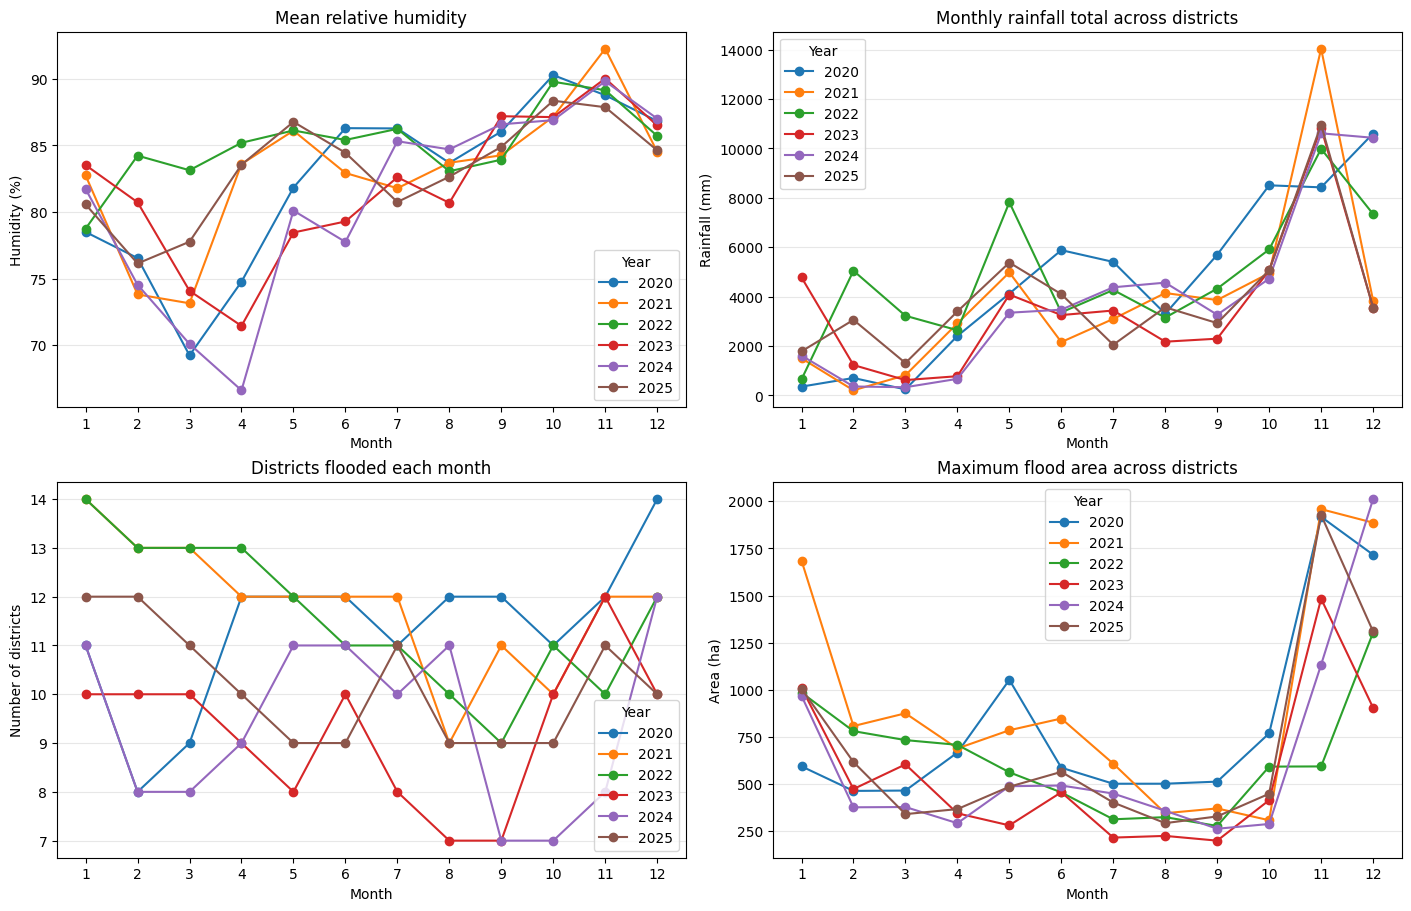

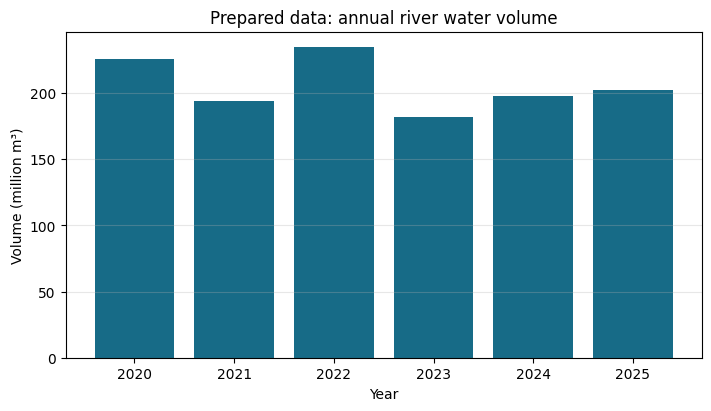

,year,month,mean_humidity_pct,rainfall_total_mm,flooded_districts,flood_area_sum_ha
0,2020,1,78.50,356.20,11,594.44
1,2020,2,76.54,705.79,8,464.13
2,2020,3,69.23,243.70,9,465.98
3,2020,4,74.76,2407.61,12,667.35
4,2020,5,81.84,4123.48,12,1053.04
5,2020,6,86.30,5882.01,12,587.15
6,2020,7,86.28,5405.52,11,502.10
7,2020,8,83.69,3304.41,12,502.26
8,2020,9,86.05,5695.87,12,513.33
9,2020,10,90.29,8507.24,11,769.40


,year,total_water_volume_mcm
0,2020,225.73
1,2021,194.16
2,2022,234.61
3,2023,182.06
4,2024,198.09
5,2025,202.26


In [5]:
merged_monthly = merged.groupby(['year', 'month'], as_index=False).agg(
    mean_humidity_pct=('humidity_mean_rh_pct', 'mean'),
    rainfall_total_mm=('monthly_rain_total_mm', 'sum'),
    flooded_districts=('flooded', 'sum'),
    flood_area_sum_ha=('max_flood_ha', 'sum'),
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
metrics = [
    ('mean_humidity_pct', 'Mean relative humidity', 'Humidity (%)'),
    ('rainfall_total_mm', 'Monthly rainfall total across districts', 'Rainfall (mm)'),
    ('flooded_districts', 'Districts flooded each month', 'Number of districts'),
    ('flood_area_sum_ha', 'Maximum flood area across districts', 'Area (ha)'),
]
for ax, (column, title, ylabel) in zip(axes.flat, metrics):
    for year in sorted(merged_monthly['year'].unique()):
        subset = merged_monthly.loc[merged_monthly['year'] == year]
        ax.plot(subset['month'], subset[column], marker='o', label=str(year))
    ax.set(title=title, xlabel='Month', ylabel=ylabel, xticks=range(1, 13))
    ax.grid(axis='y', alpha=.3)
    ax.legend(title='Year')
display(fig)
plt.close(fig)

river_by_district_year = merged.groupby(['district', 'year'], as_index=False).agg(
    river_water_volume_mcm=('river_water_volume_mcm', 'sum'),
)
river_annual = river_by_district_year.groupby('year', as_index=False).agg(
    total_water_volume_mcm=('river_water_volume_mcm', 'sum'),
)
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.bar(river_annual['year'].astype(str), river_annual['total_water_volume_mcm'], color='#176B87')
ax.set(title='Prepared data: annual river water volume', xlabel='Year', ylabel='Volume (million m³)')
ax.grid(axis='y', alpha=.3)
display(fig)
plt.close(fig)
display(merged_monthly.head(12).round(2))
display(river_annual.round(2))

## 6. บันทึกไฟล์ CSV

บันทึกข้อมูลรวมไว้ในโฟลเดอร์ `merge_dataset` เพื่อไม่ให้ไฟล์ผลลัพธ์ถูกอ่านกลับมาเป็นไฟล์ต้นทางใน `clean_data_set`

In [6]:
output_dir = root / 'merge_dataset'
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / 'NST_merged_clean_data_2020_2025.csv'
merged.to_csv(output_path, index=False, encoding='utf-8-sig', float_format='%.6f', date_format='%Y-%m-%d')
print(f'บันทึก CSV แล้ว: {output_path}')
print(f'{len(merged):,} แถว | {merged["district"].nunique()} อำเภอ | {merged["year"].min()}–{merged["year"].max()}')

บันทึก CSV แล้ว: c:\Users\sitti\OneDrive\Desktop\nahh ahhh ver nine edit - Copy\nahh ahhh\merge_dataset\NST_merged_clean_data_2020_2025.csv
1,296 แถว | 18 อำเภอ | 2020–2025
